### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** statistical forecasting of VOC: outlier removal, stationarity checks (ADF, ACF/PACF), ARIMA / auto-ARIMA, exponential smoothing (ETS), Prophet, and a simple moving-average (SMA) baseline.

**Data:** `../data/raw/voc_raw.csv.gz` (1,121,175 raw readings, ~1 s apart). The last cell reads `../data/sensors_1min.csv`; in the original run it read the old `processed_data.csv` (3–7 June), so its saved outputs come from that file.

**Split:** chronological 80/20. **Horizon:** the whole test set in one go: about 2.9 days (224,235 steps) on the raw data, and 4,074 one-minute steps spanning 75.4 hours on the 1-minute data. The last cell only plots a 100-minute forecast (no metric).

**Key result (saved output) vs baselines, 1-minute data:**

| Model | RMSE | MAE |
|---|---|---|
| ARIMA(1,1,1) | 0.2115 | 0.1476 |
| ETS (additive trend) | 0.2123 | 0.1480 |
| Prophet | 0.2271 | 0.1611 |
| SMA(5) baseline (in the notebook) | 0.2085 | 0.1463 |
| Train-mean baseline | **0.2044** | **0.1445** |

The train-mean baseline was computed later, during a review of the project. None of the models beat the simple baselines, and all have R² < 0 on this long horizon. On the raw data, auto-ARIMA picked ARIMA(0,1,0), which is exactly "repeat the last value" (RMSE 0.3664).

**Caveats**
- Outliers are found with a z-score on the **full** series (test included), and outliers are removed from the test set too, so "cleaned" and "original" results are not comparable.
- The log-ARIMA(3,0,3) result (RMSE 0.1009) did **not converge**; don't use it.
- "Number of duplicated rows" counts repeated VOC *values*, not duplicate records.
- Cells were run out of order in the original session.
- Removed during cleanup: a cell that used **synthetic random data** (its results table described noise, not the sensor), and a duplicate plot cell.
- Needs `pmdarima` and `prophet`. Uses `fillna(method=...)` and `'1T'`, which newer pandas versions deprecate.


##### CONTENTS: voc Forecasting

In [1]:
# ======================================
# INSTALL REQUIRED PYTHON LIBRARIES
# ======================================

# Uncomment the lines below to install necessary libraries if not already installed

# Install pmdarima for auto ARIMA modeling
# !pip install pmdarima

# Install core data science libraries
# !pip install pandas matplotlib seaborn statsmodels prophet

# If Prophet doesn't install from the above line, install it separately
# !pip install prophet


In [15]:
# ======================================
# DATA HANDLING & VISUALIZATION LIBRARIES
# ======================================
import pandas as pd                      # Data manipulation
import numpy as np                       # Numerical operations
import seaborn as sns                    # Statistical plotting
import matplotlib.pyplot as plt          # Plotting

sns.set_theme()  # Set seaborn theme for consistent plot styling

# ======================================
# STATIONARITY & DECOMPOSITION TOOLS
# ======================================
from scipy import stats                                  # Statistical tests
from scipy.stats import zscore                           # Z-score for outlier detection
from statsmodels.tsa.stattools import adfuller           # Augmented Dickey-Fuller test
from statsmodels.tsa.seasonal import seasonal_decompose  # Time series decomposition
from pmdarima import auto_arima

# ======================================
# AUTO-CORRELATION PLOTS
# ======================================
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # ACF and PACF plots


# ======================================
# FORECASTING MODELS
# ======================================
from statsmodels.tsa.arima.model import ARIMA                 # ARIMA model
from statsmodels.tsa.statespace.sarimax import SARIMAX        # Seasonal ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing  # Exponential Smoothing (HWES)
import statsmodels.api as sm


# ======================================
# ERROR METRICS FOR MODEL EVALUATION
# ======================================
from sklearn.metrics import mean_squared_error, mean_absolute_error  # Evaluation metrics


# ======================================
# AUTO ARIMA (MODEL SELECTION)
# ======================================
import pmdarima as pm  # Auto ARIMA for automated (p,d,q) selection


# ======================================
# PROPHET FORECASTING (FACEBOOK)
# ======================================
try:
    from prophet import Prophet
except ImportError:
    from fbprophet import Prophet

# plt.savefig("filename.png", bbox_inches='tight')


In [16]:
# ======================================
# LOAD AND PREPROCESS TIME SERIES DATA
# ======================================

# Load dataset
df = pd.read_csv("../data/raw/voc_raw.csv.gz")

# Convert 'time' column to datetime format
df['time'] = pd.to_datetime(df['time'])

# Set 'time' as the index
df.set_index('time', inplace=True)

# Display first few rows
print(df.head())

# Dataset shape
print("Shape of dataset:", df.shape)

# Check for missing values
print("Missing values:\n", df.isnull().sum())

# Check for duplicates
print("Number of duplicated rows:", df.duplicated().sum())

                                        value
time                                         
2025-06-03 00:00:00.150610304+00:00  0.545338
2025-06-03 00:00:01.196991900+00:00  0.545338
2025-06-03 00:00:02.240958760+00:00  0.545338
2025-06-03 00:00:03.597936680+00:00  0.541409
2025-06-03 00:00:04.537670287+00:00  0.541409
Shape of dataset: (1121175, 1)
Missing values:
 value    0
dtype: int64
Number of duplicated rows: 1026684


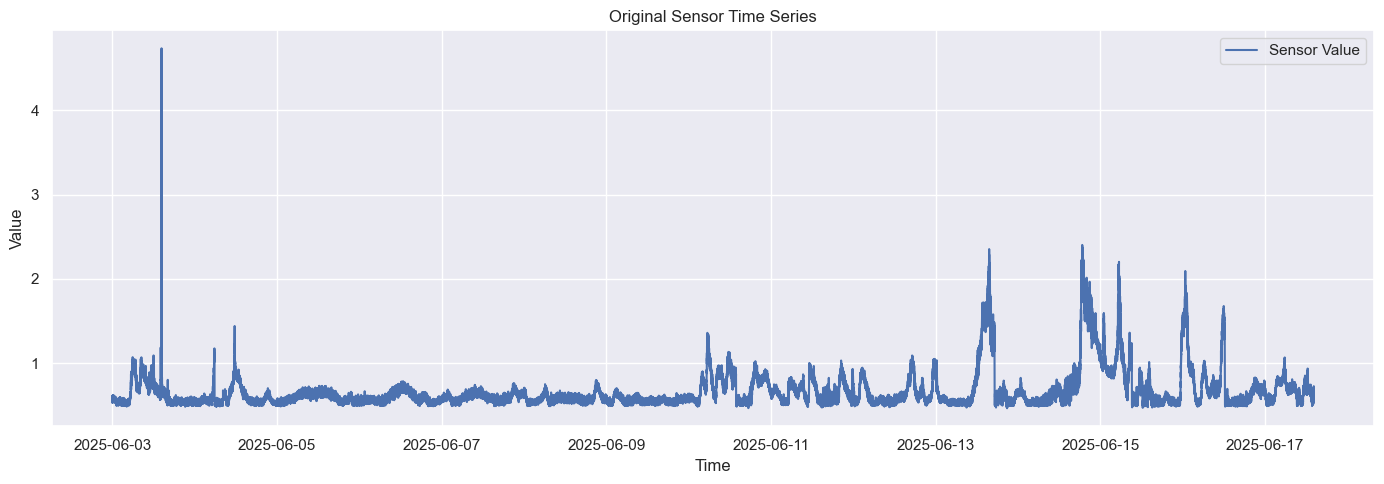

In [4]:
# ======================================
# PLOT ORIGINAL TIME SERIES
# ======================================

plt.figure(figsize=(14, 5))
plt.plot(df.index, df['value'], label='Sensor Value')
plt.title('Original Sensor Time Series')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.tight_layout()
plt.savefig("original_sensor_timeseries.png", bbox_inches='tight')  # Save the plot
plt.show()


In [17]:
# ======================================
# OUTLIER DETECTION USING Z-SCORE
# ======================================

# Calculate Z-scores of the 'value' column
df['z_score'] = stats.zscore(df['value'])

# Identify outliers with |z_score| > 3
outliers = df[np.abs(df['z_score']) > 3]
print(f"Number of outliers detected: {len(outliers)}")


Number of outliers detected: 33974


In [18]:
# ======================================
# CLEAN DATAFRAME WITHOUT OUTLIERS
# ======================================

# Keep rows where |z_score| <= 3
df_clean = df[np.abs(df['z_score']) <= 3].copy()

# Drop z_score column from cleaned data
df_clean.drop(columns='z_score', inplace=True)

# Display first few outliers
print("Sample Outliers:\n", outliers.head())


Sample Outliers:
                                         value   z_score
time                                                   
2025-06-03 14:20:15.463357205+00:00  1.489109  3.712152
2025-06-03 14:20:16.508994111+00:00  1.489109  3.712152
2025-06-03 14:20:17.553950471+00:00  1.489109  3.712152
2025-06-03 14:20:18.845653649+00:00  2.159554  6.731996
2025-06-03 14:20:19.850925642+00:00  2.159554  6.731996


In [19]:
# ======================================
# SUMMARY STATISTICS BEFORE AND AFTER OUTLIER REMOVAL
# ======================================

# Print descriptive statistics for original data
print("Original Data Stats:")
print(df['value'].describe())

# Print a blank line for spacing
print("\nCleaned Data Stats:")
print(df_clean['value'].describe())


Original Data Stats:
count    1.121175e+06
mean     6.649619e-01
std      2.220134e-01
min      4.655441e-01
25%      5.447085e-01
50%      5.877613e-01
75%      6.867367e-01
max      4.736495e+00
Name: value, dtype: float64

Cleaned Data Stats:
count    1.087201e+06
mean     6.346780e-01
std      1.377155e-01
min      4.655441e-01
25%      5.437158e-01
50%      5.840990e-01
75%      6.725369e-01
max      1.330982e+00
Name: value, dtype: float64


In [20]:
# ======================================
# MINIMUM AND MAXIMUM VALUES COMPARISON
# ======================================

# Print min and max of original data
print("Original Data Min/Max:", df['value'].min(), "/", df['value'].max())

# Print min and max of cleaned data (after removing outliers)
print("Cleaned Data Min/Max:", df_clean['value'].min(), "/", df_clean['value'].max())


Original Data Min/Max: 0.4655441045761108 / 4.736495494842529
Cleaned Data Min/Max: 0.4655441045761108 / 1.3309824466705322


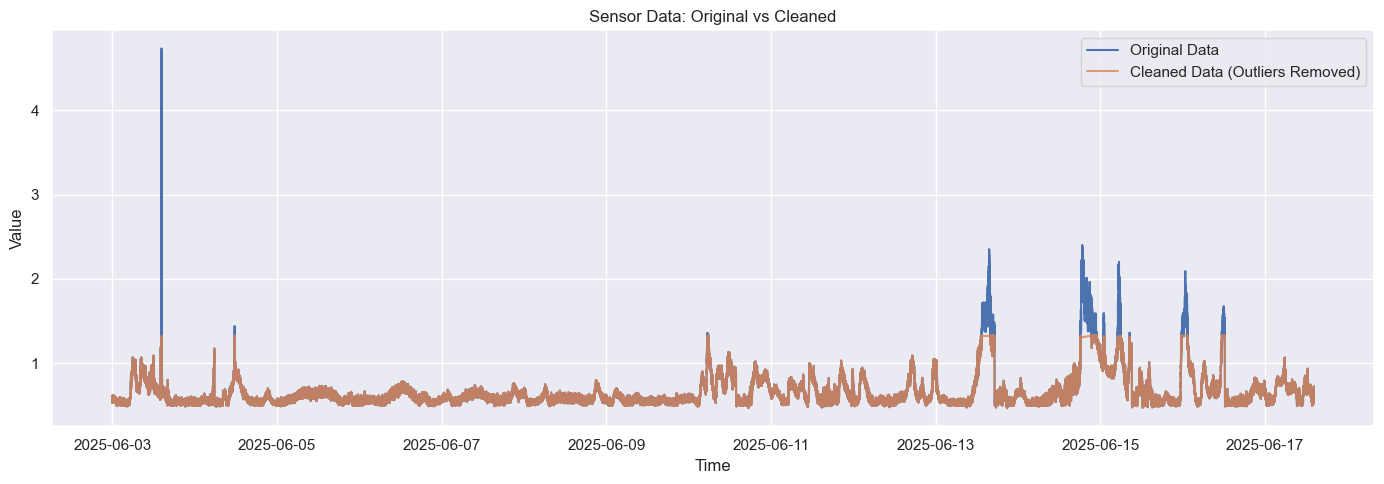

In [10]:
# ======================================
# PLOT ORIGINAL VS CLEANED SENSOR DATA
# ======================================

plt.figure(figsize=(14, 5))

# Plot original data with full range (including outliers)
plt.plot(df.index, df['value'], label='Original Data')

# Plot cleaned data (outliers removed)
plt.plot(df_clean.index, df_clean['value'], label='Cleaned Data (Outliers Removed)', alpha=0.8)

# Add title and axis labels
plt.title('Sensor Data: Original vs Cleaned')
plt.xlabel('Time')
plt.ylabel('Value')

# Show legend
plt.legend()

# Save plot to file
plt.tight_layout()
plt.savefig("sensor_data_original_vs_cleaned.png", bbox_inches='tight')

# Display plot
plt.show()


In [21]:
# ======================================
# TRAIN-TEST SPLIT FOR ORIGINAL & CLEANED DATA
# ======================================

# Define train-test split ratio (80% train, 20% test)
split_ratio = 0.8

# -------- Original Data Split --------
split_index_orig = int(len(df) * split_ratio)
train_orig = df.iloc[:split_index_orig]['value']  # Training set
test_orig = df.iloc[split_index_orig:]['value']   # Testing set

# -------- Cleaned Data Split --------
split_index_clean = int(len(df_clean) * split_ratio)
train_clean = df_clean.iloc[:split_index_clean]['value']
test_clean = df_clean.iloc[split_index_clean:]['value']

# Print sizes of splits
print(f"Original train size: {len(train_orig)}, test size: {len(test_orig)}")
print(f"Cleaned train size: {len(train_clean)}, test size: {len(test_clean)}")


Original train size: 896940, test size: 224235
Cleaned train size: 869760, test size: 217441


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:               896940
Model:               SARIMAX(0, 1, 0)   Log Likelihood             3173757.323
Date:                Sun, 22 Jun 2025   AIC                       -6347512.645
Time:                        19:10:54   BIC                       -6347500.939
Sample:                             0   HQIC                      -6347509.409
                             - 896940                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      4.944e-05   3.65e-09   1.35e+04      0.000    4.94e-05    4.94e-05
Ljung-Box (L1) (Q):                   0.27   Jarque-Bera (JB):       24871877010.93
Prob(Q):                              0.60   Pr

ARIMA Original Data RMSE: 0.3664
ARIMA Original Data MAE: 0.2349


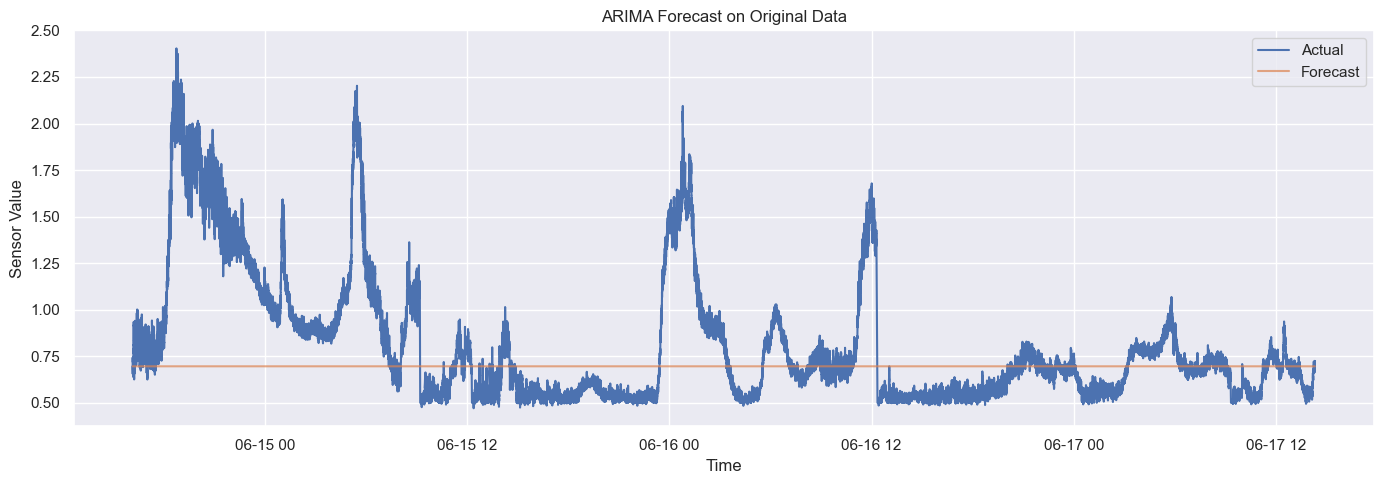

In [12]:
# ======================================
# FIT AUTO_ARIMA MODEL TO ORIGINAL TRAINING DATA
# ======================================

# Automatically find the best ARIMA (p,d,q) parameters
arima_model_orig = pm.auto_arima(
    train_orig,
    seasonal=False,            # No seasonality
    stepwise=True,             # Use stepwise search for efficiency
    suppress_warnings=True     # Ignore convergence warnings
)

# Print model summary
print(arima_model_orig.summary())

# Optional: Save model if needed later
# import joblib
# joblib.dump(arima_model_orig, "arima_model_orig.pkl")

# ======================================
# FORECAST & EVALUATE AUTO_ARIMA ON ORIGINAL DATA
# ======================================

# Forecast for the same number of periods as in the test set
forecast_orig = arima_model_orig.predict(n_periods=len(test_orig))

# Evaluate the forecast using RMSE and MAE
rmse_orig = mean_squared_error(test_orig, forecast_orig, squared=False)  # Root Mean Squared Error
mae_orig = mean_absolute_error(test_orig, forecast_orig)                # Mean Absolute Error

# Print evaluation metrics
print(f"ARIMA Original Data RMSE: {rmse_orig:.4f}")
print(f"ARIMA Original Data MAE: {mae_orig:.4f}")


# ======================================
# PLOT ACTUAL VS FORECASTED VALUES FOR ORIGINAL DATA
# ======================================

plt.figure(figsize=(14, 5))

# Plot actual test data
plt.plot(test_orig.index, test_orig, label='Actual')

# Plot ARIMA forecasted values
plt.plot(test_orig.index, forecast_orig, label='Forecast', alpha=0.7)

# Add titles and labels
plt.title('ARIMA Forecast on Original Data')
plt.xlabel('Time')
plt.ylabel('Sensor Value')

# Show legend
plt.legend()

# Save plot to file
plt.tight_layout()
plt.savefig("arima_forecast_original_data.png", bbox_inches='tight')

# Display plot
plt.show()

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:               869760
Model:               SARIMAX(0, 1, 0)   Log Likelihood             3141873.638
Date:                Sun, 22 Jun 2025   AIC                       -6283745.276
Time:                        19:30:05   BIC                       -6283733.600
Sample:                             0   HQIC                      -6283742.045
                             - 869760                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      4.265e-05   4.88e-09   8741.962      0.000    4.26e-05    4.27e-05
Ljung-Box (L1) (Q):                   0.37   Jarque-Bera (JB):        4426346362.88
Prob(Q):                              0.54   Pr

ARIMA Cleaned Data RMSE: 0.2052
ARIMA Cleaned Data MAE: 0.1453


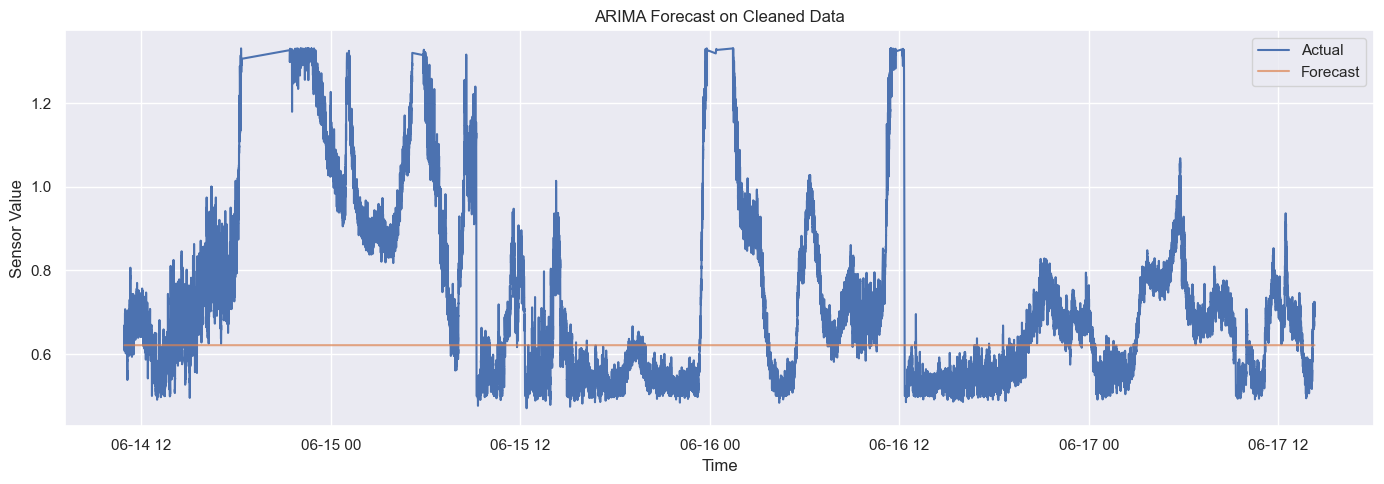

In [13]:
# ======================================
# FIT AUTO_ARIMA MODEL TO CLEANED TRAINING DATA
# ======================================
arima_model_clean = pm.auto_arima(
    train_clean,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True
)

# Print model summary
print(arima_model_clean.summary())

# ======================================
# FORECAST & EVALUATE ON CLEANED TEST DATA
# ======================================
forecast_clean = arima_model_clean.predict(n_periods=len(test_clean))

rmse_clean = mean_squared_error(test_clean, forecast_clean, squared=False)
mae_clean = mean_absolute_error(test_clean, forecast_clean)

print(f"ARIMA Cleaned Data RMSE: {rmse_clean:.4f}")
print(f"ARIMA Cleaned Data MAE: {mae_clean:.4f}")

# ======================================
# PLOT ACTUAL VS FORECASTED VALUES (CLEANED DATA)
# ======================================
plt.figure(figsize=(14, 5))
plt.plot(test_clean.index, test_clean, label='Actual')
plt.plot(test_clean.index, forecast_clean, label='Forecast', alpha=0.7)
plt.title('ARIMA Forecast on Cleaned Data')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()
plt.tight_layout()
plt.savefig("arima_forecast_cleaned_data.png", bbox_inches='tight')  # Save plot
plt.show()

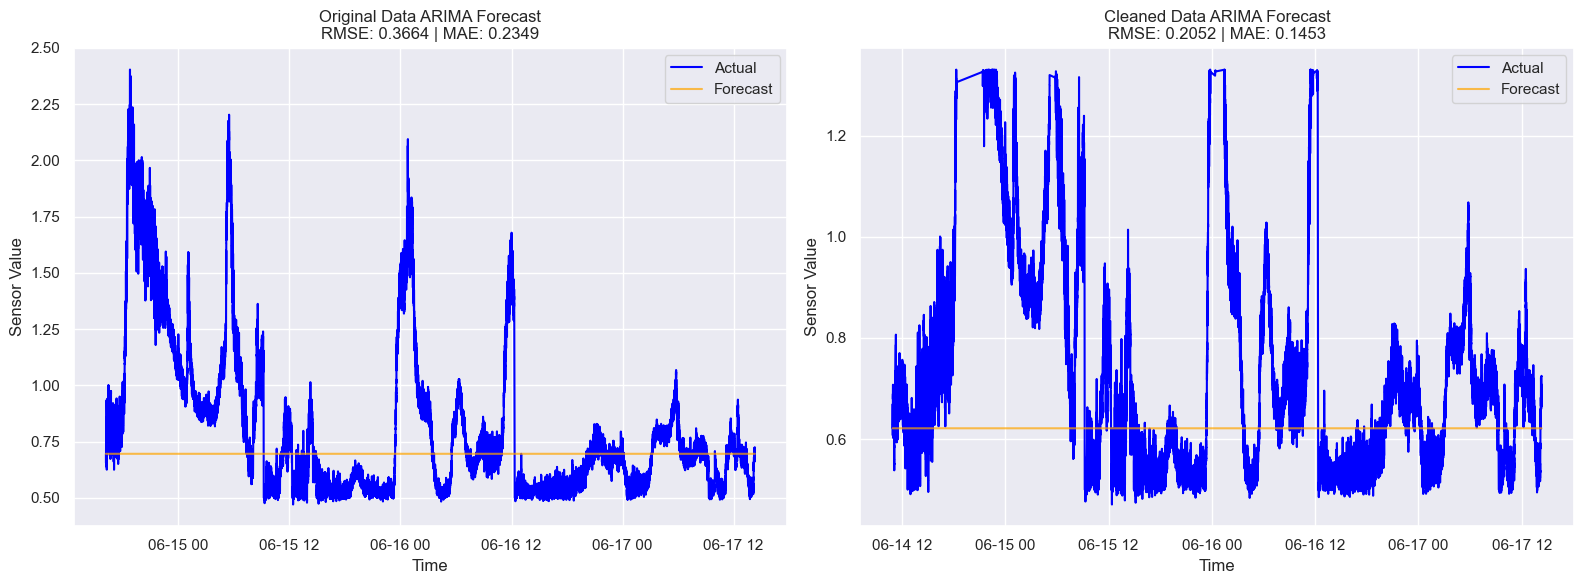

=== ARIMA Model Comparison ===
Original Data -> RMSE: 0.3664, MAE: 0.2349
Cleaned Data  -> RMSE: 0.2052, MAE: 0.1453


In [14]:
# ======================================
# COMPARE ARIMA FORECASTS: ORIGINAL VS CLEANED DATA
# ======================================

# Combine actual and forecasts for easier plotting

plt.figure(figsize=(16, 6))

# Plot Original Data Forecast
plt.subplot(1, 2, 1)
plt.plot(test_orig.index, test_orig, label='Actual', color='blue')
plt.plot(test_orig.index, forecast_orig, label='Forecast', alpha=0.7, color='orange')
plt.title(f'Original Data ARIMA Forecast\nRMSE: {rmse_orig:.4f} | MAE: {mae_orig:.4f}')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()

# Plot Cleaned Data Forecast
plt.subplot(1, 2, 2)
plt.plot(test_clean.index, test_clean, label='Actual', color='blue')
plt.plot(test_clean.index, forecast_clean, label='Forecast', alpha=0.7, color='orange')
plt.title(f'Cleaned Data ARIMA Forecast\nRMSE: {rmse_clean:.4f} | MAE: {mae_clean:.4f}')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()

plt.tight_layout()
plt.savefig("arima_forecast_comparison.png", bbox_inches='tight')
plt.show()

# Optional: Print summary comparison
print("=== ARIMA Model Comparison ===")
print(f"Original Data -> RMSE: {rmse_orig:.4f}, MAE: {mae_orig:.4f}")
print(f"Cleaned Data  -> RMSE: {rmse_clean:.4f}, MAE: {mae_clean:.4f}")

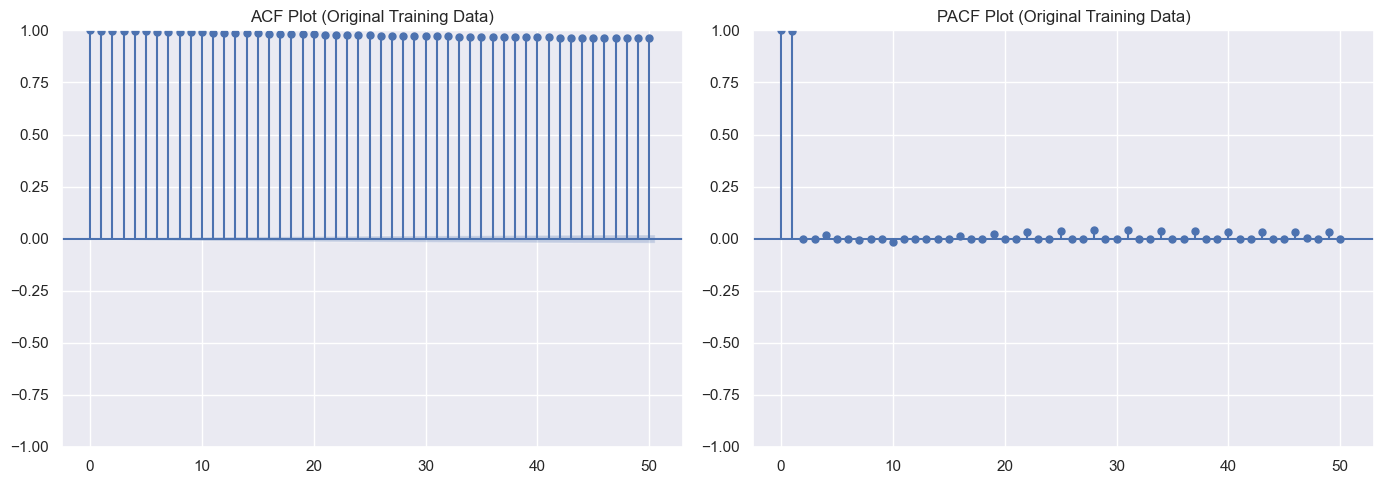

In [15]:
# ======================================
# ACF and PACF PLOTS FOR ORIGINAL TRAINING DATA
# ======================================
plt.figure(figsize=(14, 5))

# Plot ACF of original training data
plt.subplot(1, 2, 1)
plot_acf(train_orig, lags=50, ax=plt.gca())
plt.title('ACF Plot (Original Training Data)')

# Plot PACF of original training data
plt.subplot(1, 2, 2)
plot_pacf(train_orig, lags=50, ax=plt.gca(), method='ywm')
plt.title('PACF Plot (Original Training Data)')

plt.tight_layout()
plt.savefig("acf_pacf_original_train.png", bbox_inches='tight')
plt.show()

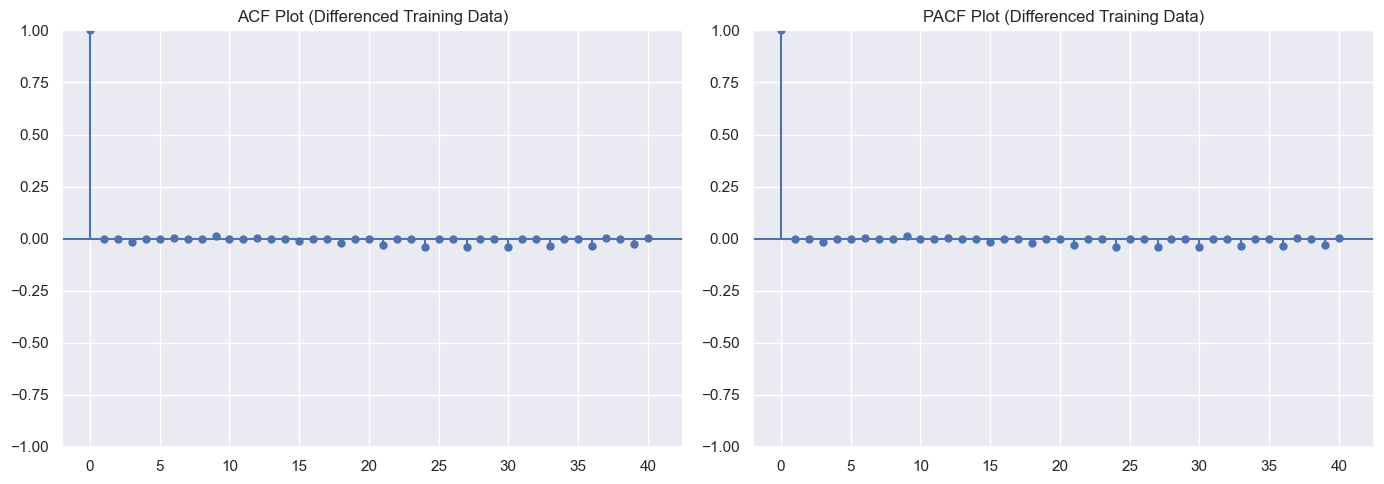

In [16]:
# ======================================
# DIFFERENCE THE TRAINING SERIES TO REMOVE TREND (d=1)
# ======================================
diff_train = train_orig.diff().dropna()

# ======================================
# ACF and PACF PLOTS FOR DIFFERENCED TRAINING DATA
# ======================================
plt.figure(figsize=(14, 5))

# Plot ACF of differenced training data
plt.subplot(1, 2, 1)
plot_acf(diff_train, lags=40, ax=plt.gca())
plt.title('ACF Plot (Differenced Training Data)')

# Plot PACF of differenced training data
plt.subplot(1, 2, 2)
plot_pacf(diff_train, lags=40, ax=plt.gca(), method='ywm')
plt.title('PACF Plot (Differenced Training Data)')

plt.tight_layout()
plt.savefig("acf_pacf_differenced_train.png", bbox_inches='tight')
plt.show()


In [17]:
# ======================================
# COMPARE SEVERAL ARIMA MODELS ON ORIGINAL DATA
# ======================================
models = {
    'ARIMA(1,1,0)': (1, 1, 0),
    'ARIMA(0,1,1)': (0, 1, 1),
    'ARIMA(1,1,1)': (1, 1, 1)
}

results = {}

for name, order in models.items():
    model = ARIMA(train_orig, order=order)
    model_fit = model.fit()
    pred = model_fit.forecast(steps=len(test_orig))
    rmse = np.sqrt(mean_squared_error(test_orig, pred))
    mae = mean_absolute_error(test_orig, pred)
    results[name] = {'RMSE': rmse, 'MAE': mae}
    print(f"{name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}")

ARIMA(1,1,0) -> RMSE: 0.3664, MAE: 0.2349


ARIMA(0,1,1) -> RMSE: 0.3664, MAE: 0.2349


ARIMA(1,1,1) -> RMSE: 0.3664, MAE: 0.2349


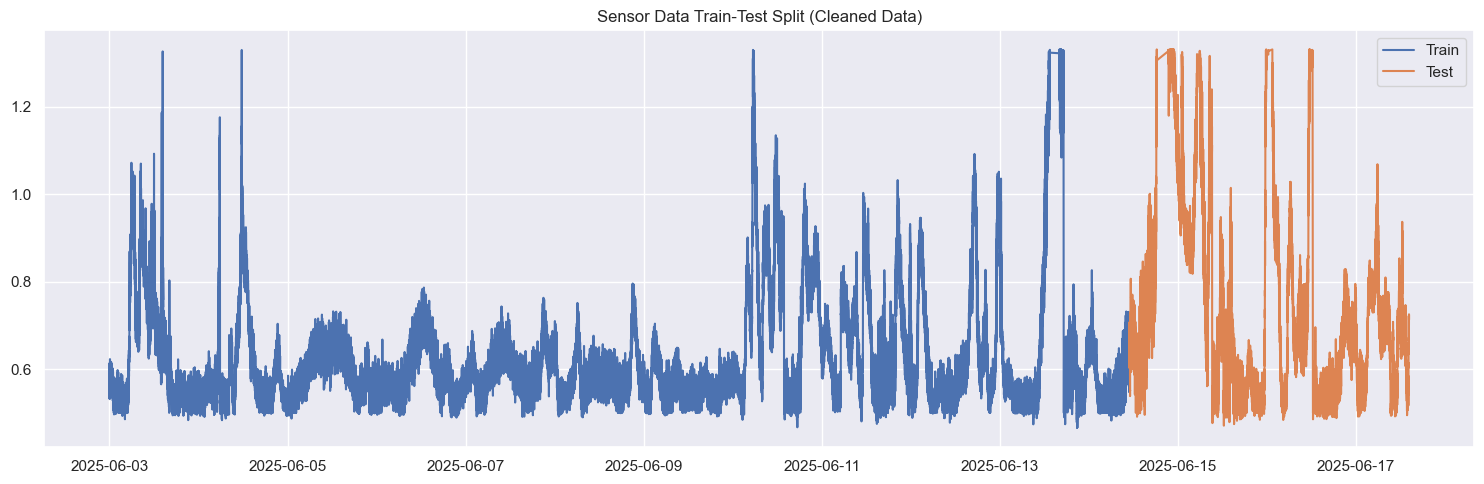

In [18]:
# ======================================
# TRAIN-TEST SPLIT ON CLEANED DATA
# ======================================
train_size = int(len(df_clean) * 0.8)
train = df_clean.iloc[:train_size]['value']
test = df_clean.iloc[train_size:]['value']

plt.figure(figsize=(15, 5))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.title('Sensor Data Train-Test Split (Cleaned Data)')
plt.legend()
plt.tight_layout()
plt.savefig("train_test_split_cleaned.png", bbox_inches='tight')
plt.show()

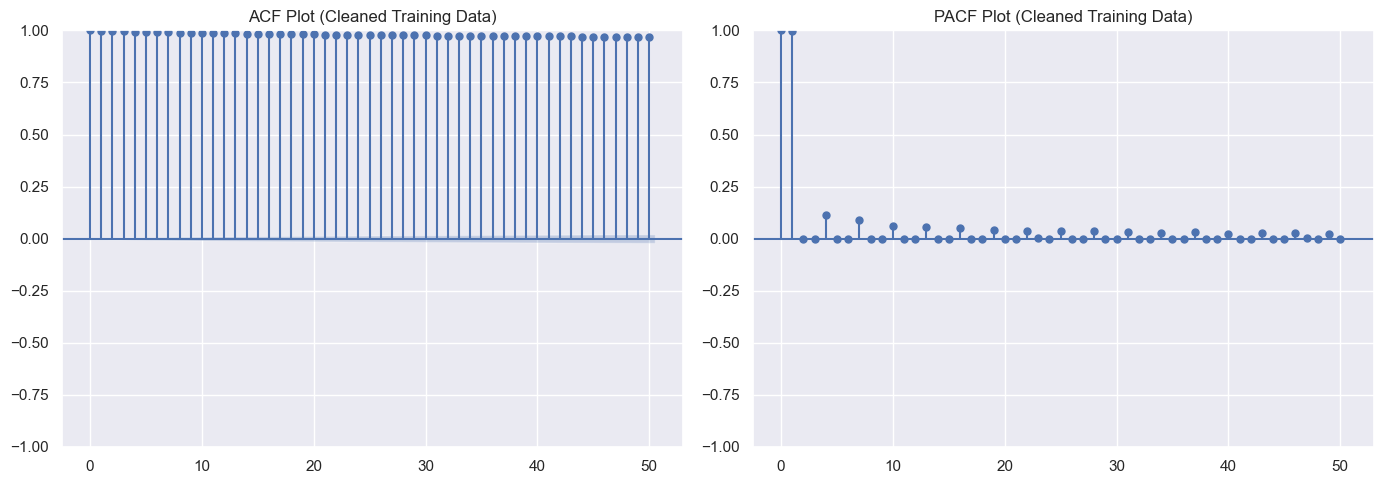

In [19]:
# ======================================
# ACF & PACF PLOTS ON CLEANED TRAINING DATA
# ======================================
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plot_acf(train, lags=50, ax=plt.gca())
plt.title('ACF Plot (Cleaned Training Data)')

plt.subplot(1, 2, 2)
plot_pacf(train, lags=50, ax=plt.gca(), method='ywm')
plt.title('PACF Plot (Cleaned Training Data)')

plt.tight_layout()
plt.savefig("acf_pacf_cleaned_train.png", bbox_inches='tight')
plt.show()

In [22]:
# ======================================
# FIT ARIMA(1,1,1) ON CLEANED TRAINING DATA
# ======================================
model = sm.tsa.ARIMA(train, order=(1, 1, 1))
model_fit = model.fit()
print(model_fit.summary())

# Forecast on test set
forecast = model_fit.forecast(steps=len(test))

                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:               869760
Model:                 ARIMA(1, 1, 1)   Log Likelihood             3141873.638
Date:                Sun, 22 Jun 2025   AIC                       -6283741.276
Time:                        20:04:13   BIC                       -6283706.248
Sample:                             0   HQIC                      -6283731.582
                             - 869760                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1      -4.557e-11      0.001   -3.4e-08      1.000      -0.003       0.003
ma.L1      -4.627e-11      0.001  -3.45e-08      1.000      -0.003       0.003
sigma2      4.265e-05   7.72e-09   5522.223      0.0

ETS Model RMSE: 0.2031
ETS Model MAE: 0.1445


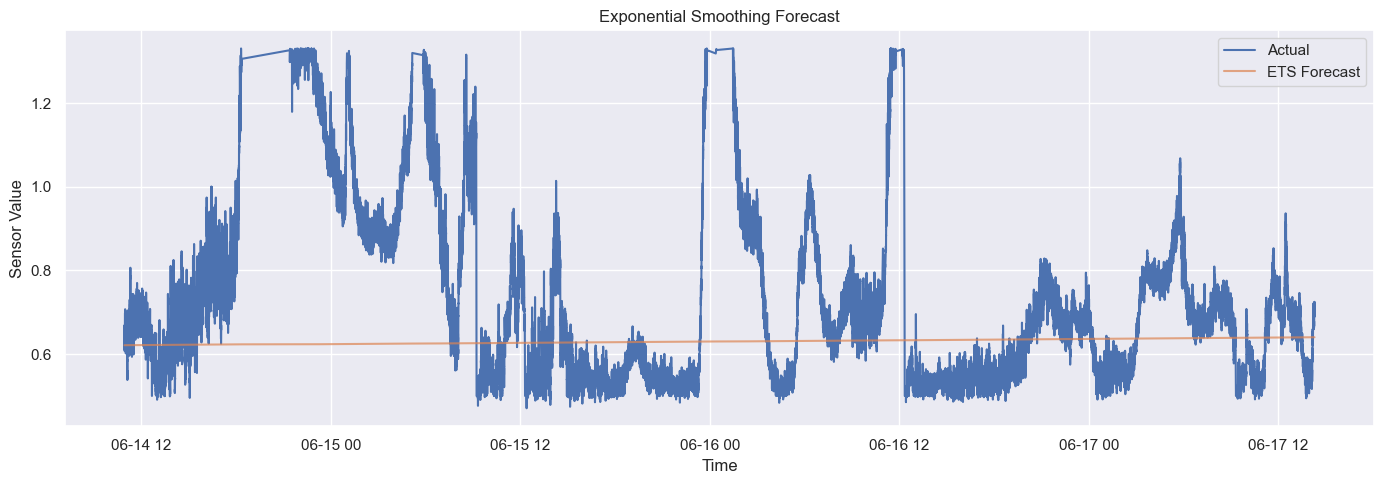

In [23]:
# ======================================
# FIT EXPONENTIAL SMOOTHING MODEL ON TRAINING DATA
# ======================================
ets_model = ExponentialSmoothing(train, trend='add', seasonal=None)
ets_fit = ets_model.fit()

# FORECAST ON TEST SET
ets_forecast = ets_fit.forecast(len(test))

# ======================================
# EVALUATE THE ETS MODEL
# ======================================
rmse_ets = mean_squared_error(test, ets_forecast, squared=False)
mae_ets = mean_absolute_error(test, ets_forecast)

print(f"ETS Model RMSE: {rmse_ets:.4f}")
print(f"ETS Model MAE: {mae_ets:.4f}")

# ======================================
# PLOT ACTUAL VS FORECASTED VALUES
# ======================================
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label='Actual')
plt.plot(test.index, ets_forecast, label='ETS Forecast', alpha=0.7)
plt.title('Exponential Smoothing Forecast')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.legend()
plt.tight_layout()
plt.savefig("ets_forecast.png", bbox_inches='tight')
plt.show()


ARIMA -> RMSE: 0.2052, MAE: 0.1453
ETS -> RMSE: 0.2031, MAE: 0.1445


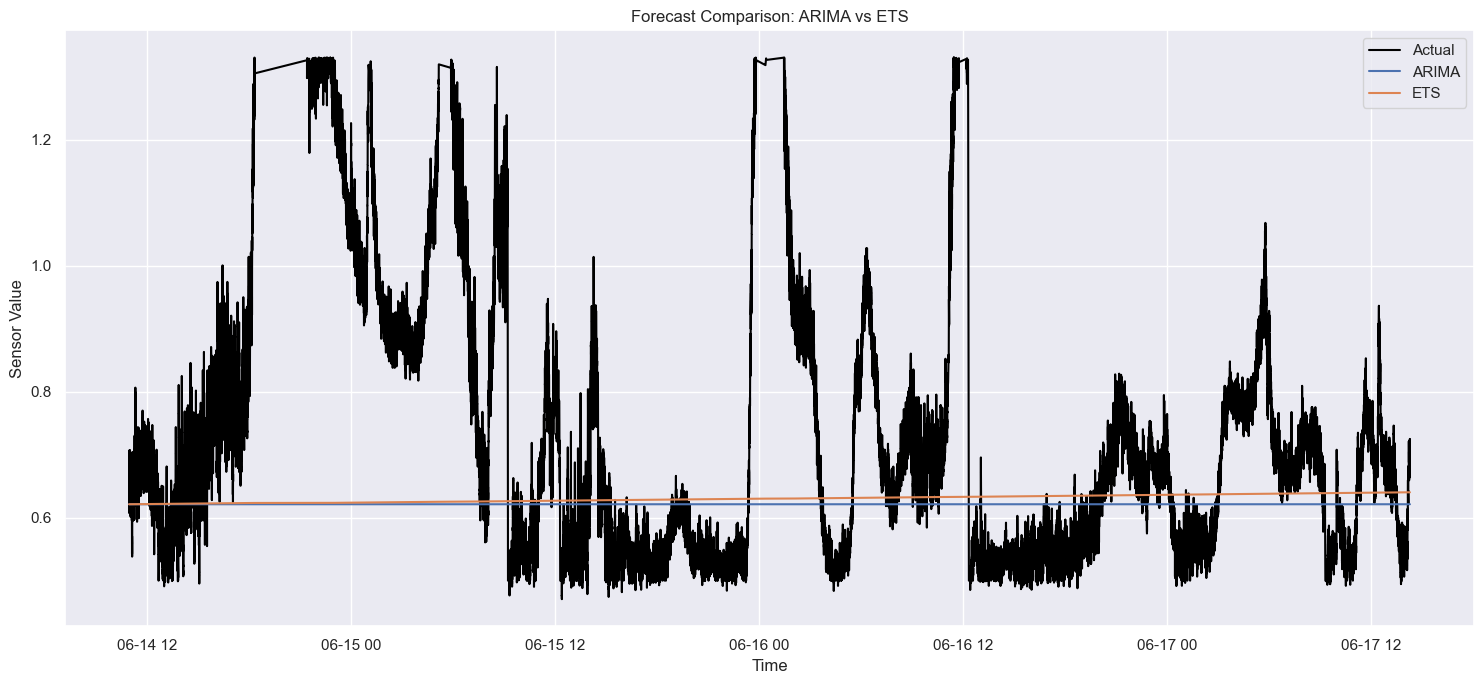

In [24]:
# ======================================
# FUNCTION TO EVALUATE AND PRINT MODEL ERRORS
# ======================================
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{model_name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    return rmse, mae

# Evaluate ARIMA forecast
rmse_arima, mae_arima = evaluate_model(test, forecast, 'ARIMA')

# Evaluate ETS forecast
rmse_ets, mae_ets = evaluate_model(test, ets_forecast, 'ETS')

# ======================================
# PLOT ACTUAL VS FORECASTED VALUES FOR BOTH MODELS
# ======================================
plt.figure(figsize=(15, 7))

plt.plot(test.index, test, label='Actual', color='black')
plt.plot(test.index, forecast, label='ARIMA')
plt.plot(test.index, ets_forecast, label='ETS')

plt.legend()
plt.title('Forecast Comparison: ARIMA vs ETS')
plt.xlabel('Time')
plt.ylabel('Sensor Value')
plt.tight_layout()
plt.savefig("forecast_comparison_arima_ets.png", bbox_inches='tight')
plt.show()

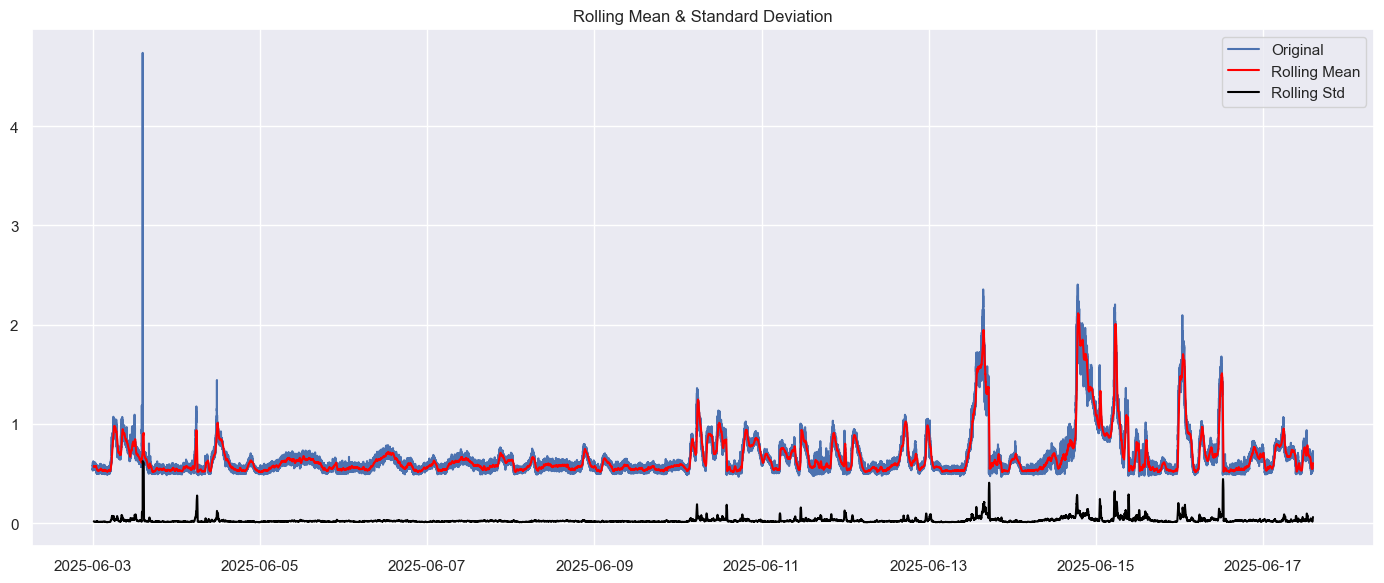

In [25]:
# ======================================
# PLOT ROLLING MEAN AND STANDARD DEVIATION
# ======================================
rolling_mean = df['value'].rolling(window=1000).mean()
rolling_std = df['value'].rolling(window=1000).std()

plt.figure(figsize=(14, 6))
plt.plot(df['value'], label='Original')
plt.plot(rolling_mean, label='Rolling Mean', color='red')
plt.plot(rolling_std, label='Rolling Std', color='black')
plt.legend()
plt.title("Rolling Mean & Standard Deviation")
plt.grid(True)

plt.tight_layout()
plt.savefig("rolling_mean_std.png", bbox_inches='tight')
plt.show()

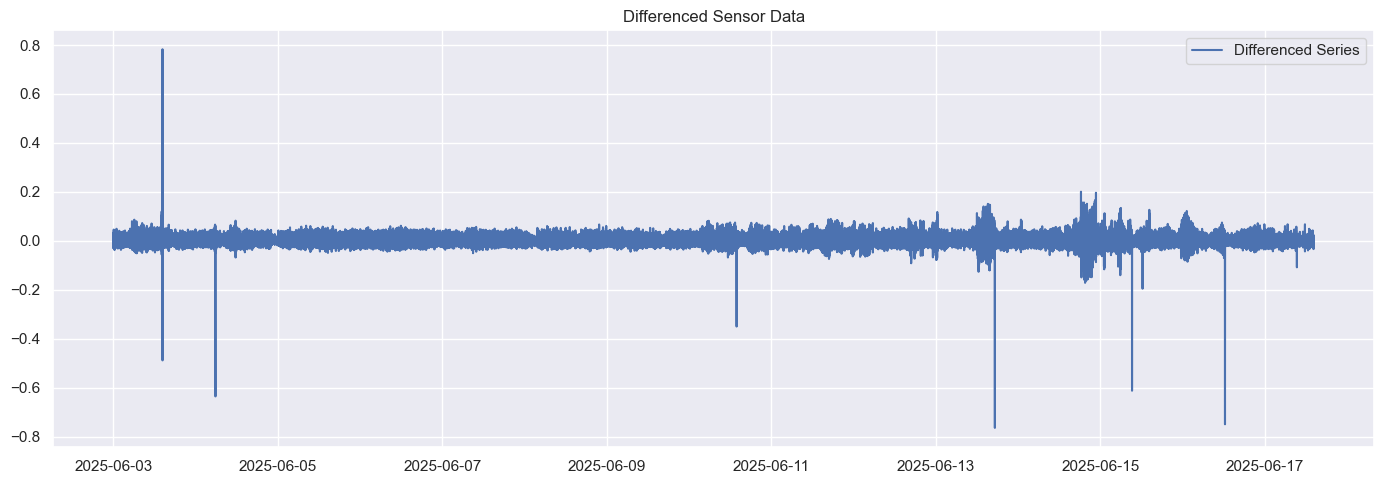

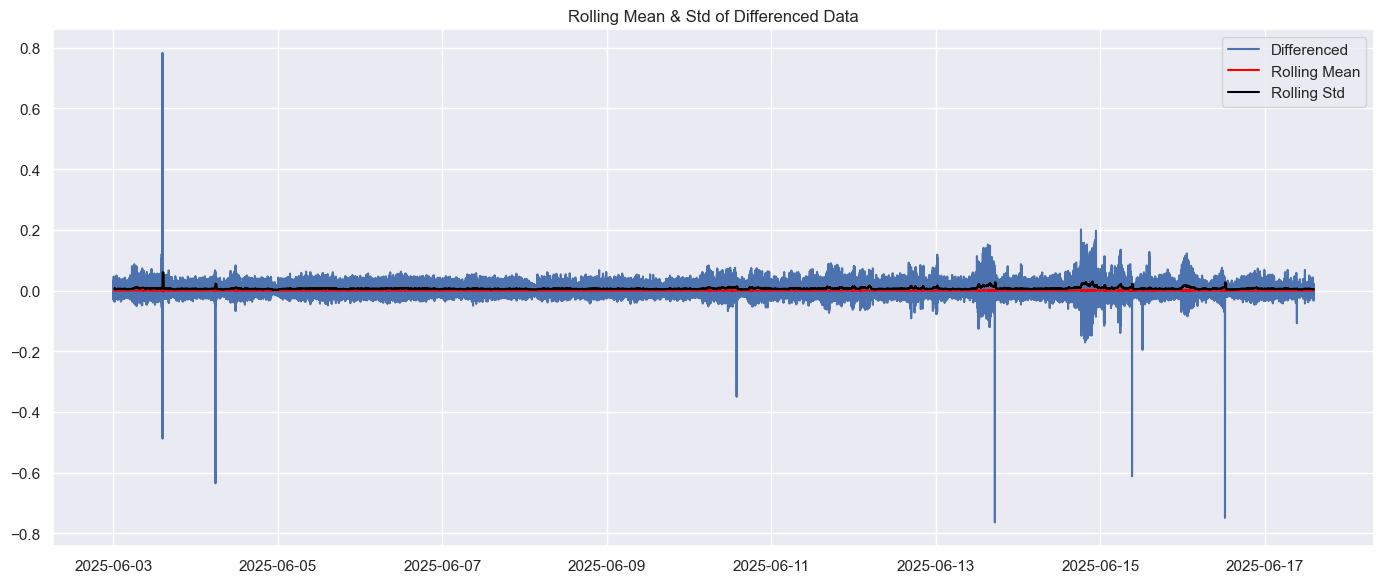

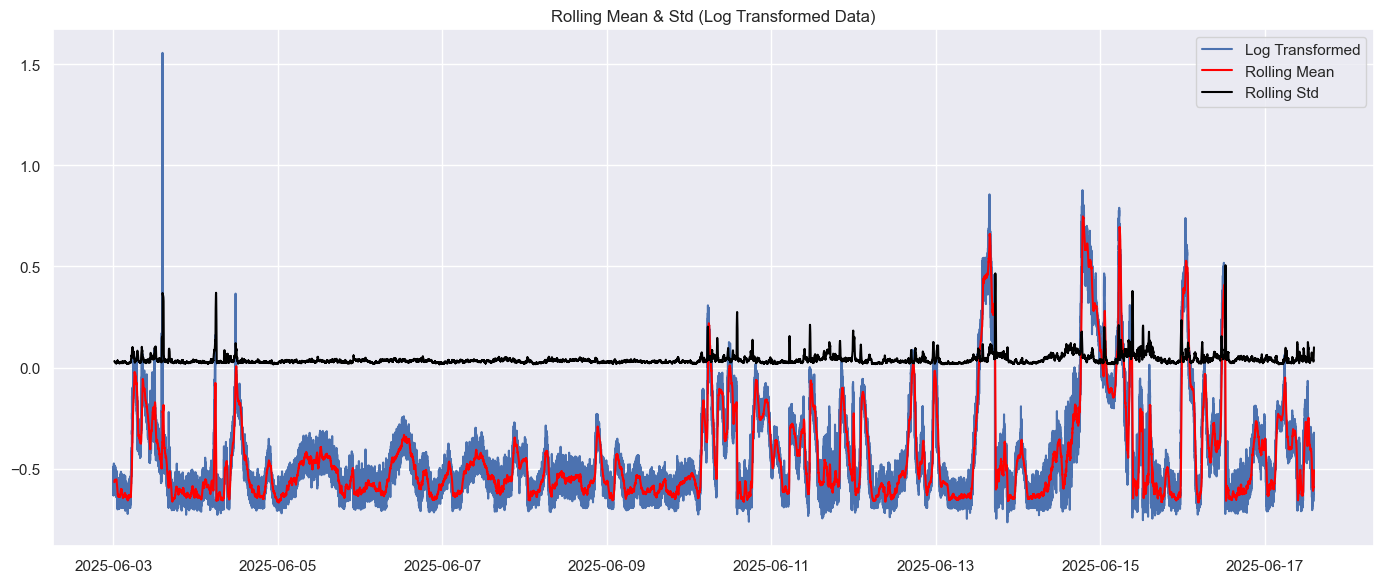

In [ ]:
# ======================================
# DIFFERENCING THE SERIES TO REMOVE TREND
# ======================================
df_diff = df['value'].diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(df_diff, label='Differenced Series')
plt.title("Differenced Sensor Data")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("differenced_series.png", bbox_inches='tight')
plt.show()

# ======================================
# ROLLING MEAN & STD OF DIFFERENCED DATA
# ======================================
rolling_mean_diff = df_diff.rolling(window=1000).mean()
rolling_std_diff = df_diff.rolling(window=1000).std()

plt.figure(figsize=(14, 6))
plt.plot(df_diff, label='Differenced')
plt.plot(rolling_mean_diff, label='Rolling Mean', color='red')
plt.plot(rolling_std_diff, label='Rolling Std', color='black')
plt.legend()
plt.title("Rolling Mean & Std of Differenced Data")
plt.grid(True)
plt.tight_layout()
plt.savefig("rolling_mean_std_differenced.png", bbox_inches='tight')
plt.show()

# ======================================
# LOG TRANSFORMATION TO STABILIZE VARIANCE
# ======================================
df_log = np.log(df['value'])

rolling_mean_log = df_log.rolling(window=1000).mean()
rolling_std_log = df_log.rolling(window=1000).std()

plt.figure(figsize=(14, 6))
plt.plot(df_log, label='Log Transformed')
plt.plot(rolling_mean_log, label='Rolling Mean', color='red')
plt.plot(rolling_std_log, label='Rolling Std', color='black')
plt.legend()
plt.title("Rolling Mean & Std (Log Transformed Data)")
plt.grid(True)
plt.tight_layout()
plt.savefig("rolling_mean_std_log_transformed.png", bbox_inches='tight')
plt.show()

# ======================================
# AUGMENTED DICKEY-FULLER TEST ON LOG-TRANSFORMED DATA
# ======================================
result = adfuller(df_log.dropna())
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value}")


In [8]:
# ======================================
# TRAIN-TEST SPLIT ON LOG-TRANSFORMED DATA (80%-20%)
# ======================================
df_log = np.log(df['value'])

train_size = int(len(df_log) * 0.8)
train_log, test_log = df_log[:train_size], df_log[train_size:]

ARIMA(1,0,1) on Log-Transformed Data
RMSE: 0.3984
MAE: 0.2450


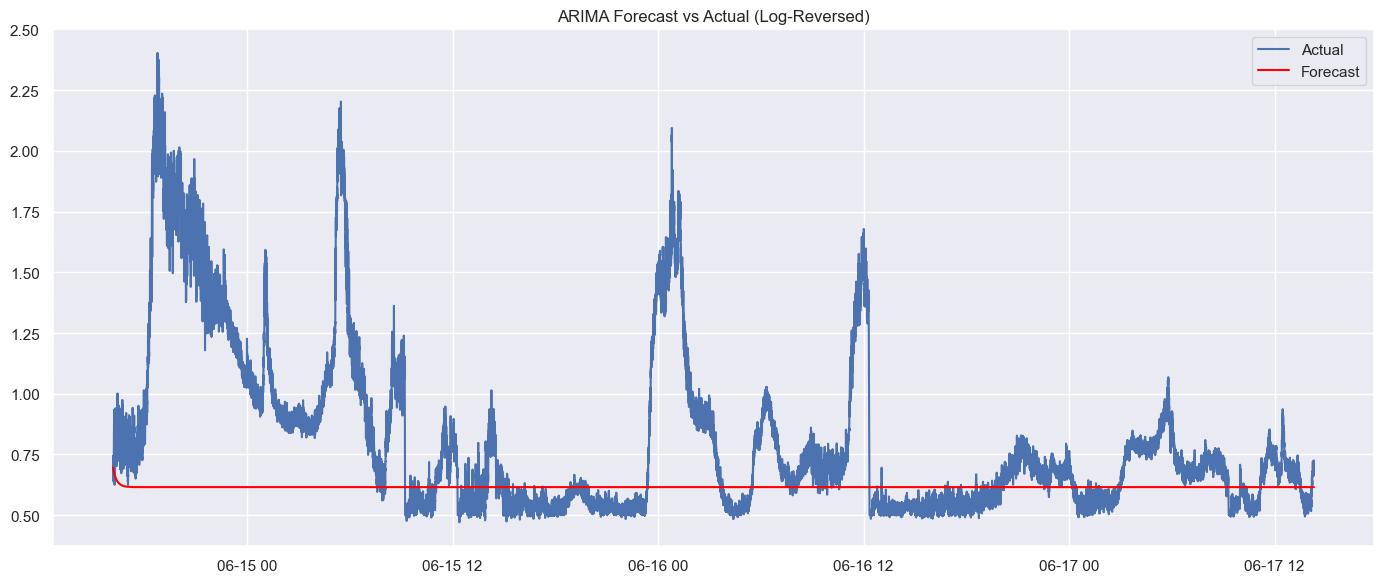

In [5]:
# ======================================
# FIT ARIMA(1,0,1) ON LOG-TRANSFORMED TRAIN DATA
# ======================================
model = ARIMA(train_log, order=(1, 0, 1))
model_fit = model.fit()

# FORECAST LOG-TRANSFORMED TEST PERIOD
forecast_log = model_fit.forecast(steps=len(test_log))

# REVERSE LOG TRANSFORM TO ORIGINAL SCALE
forecast = np.exp(forecast_log)
actual = np.exp(test_log)

# EVALUATE MODEL PERFORMANCE
rmse = np.sqrt(mean_squared_error(actual, forecast))
mae = mean_absolute_error(actual, forecast)

print("ARIMA(1,0,1) on Log-Transformed Data")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

# PLOT FORECAST VS ACTUAL
plt.figure(figsize=(14, 6))
plt.plot(actual.index, actual, label='Actual')
plt.plot(actual.index, forecast, label='Forecast', color='red')
plt.legend()
plt.title("ARIMA Forecast vs Actual (Log-Reversed)")
plt.grid(True)
plt.tight_layout()
plt.savefig("arima_log_reversed_forecast.png", bbox_inches='tight')
plt.show()

In [23]:
# ======================================
# FIT ARIMA(3,0,3) ON LOG-TRANSFORMED TRAIN DATA
# ======================================
model = ARIMA(train_log, order=(3, 0, 3))
model_fit = model.fit()

forecast_log = model_fit.forecast(steps=len(test_log))

forecast = np.exp(forecast_log)
actual = np.exp(test_log)

rmse = np.sqrt(mean_squared_error(actual, forecast))
mae = mean_absolute_error(actual, forecast)

print("ARIMA(3,0,3) on Log-Transformed Data")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

ARIMA(3,0,3) on Log-Transformed Data
RMSE: 0.1009
MAE: 0.0825


In [22]:
# ======================================
# EXPONENTIAL SMOOTHING (ETS) MODEL ON ORIGINAL TRAIN DATA
# ======================================
model_ets = ExponentialSmoothing(train_orig, trend='add', seasonal=None)
model_fit_ets = model_ets.fit()

forecast_ets = model_fit_ets.forecast(len(test_orig))

rmse_ets = np.sqrt(mean_squared_error(test_orig, forecast_ets))
mae_ets = mean_absolute_error(test_orig, forecast_ets)

print("ETS Model on Original Data")
print(f"RMSE: {rmse_ets:.4f}")
print(f"MAE: {mae_ets:.4f}")

ETS Model on Original Data
RMSE: 0.3661
MAE: 0.2398


Missing 1-minute intervals: 2


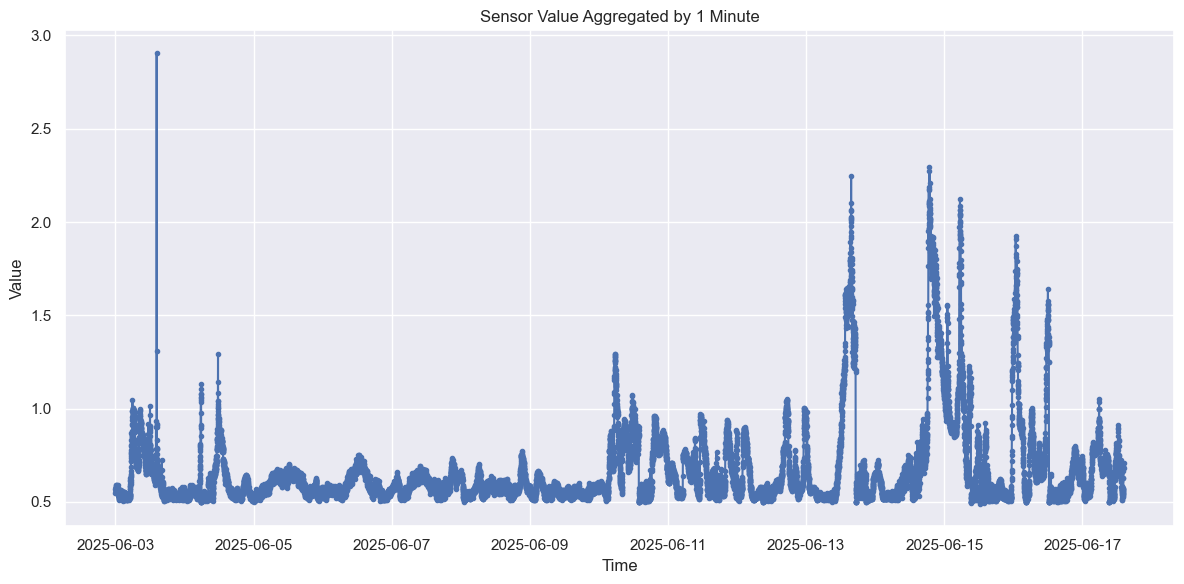

In [34]:
# ======================================
# RESAMPLE DATA TO 1-MINUTE INTERVALS (MEAN AGGREGATION)
# ======================================
df_1min = df['value'].resample('1T').mean()

# CHECK MISSING MINUTES
missing = df_1min.isna().sum()
print(f"Missing 1-minute intervals: {missing}")

# FORWARD FILL MISSING VALUES
df_1min.fillna(method='ffill', inplace=True)

# PLOT RESAMPLED TIME SERIES
plt.figure(figsize=(12, 6))
plt.plot(df_1min, marker='.', linestyle='-')
plt.title('Sensor Value Aggregated by 1 Minute')
plt.xlabel('Time')
plt.ylabel('Value')
plt.grid(True)
plt.tight_layout()
plt.savefig("resampled_1min_timeseries.png", bbox_inches='tight')
plt.show()



Number of outliers detected: 649


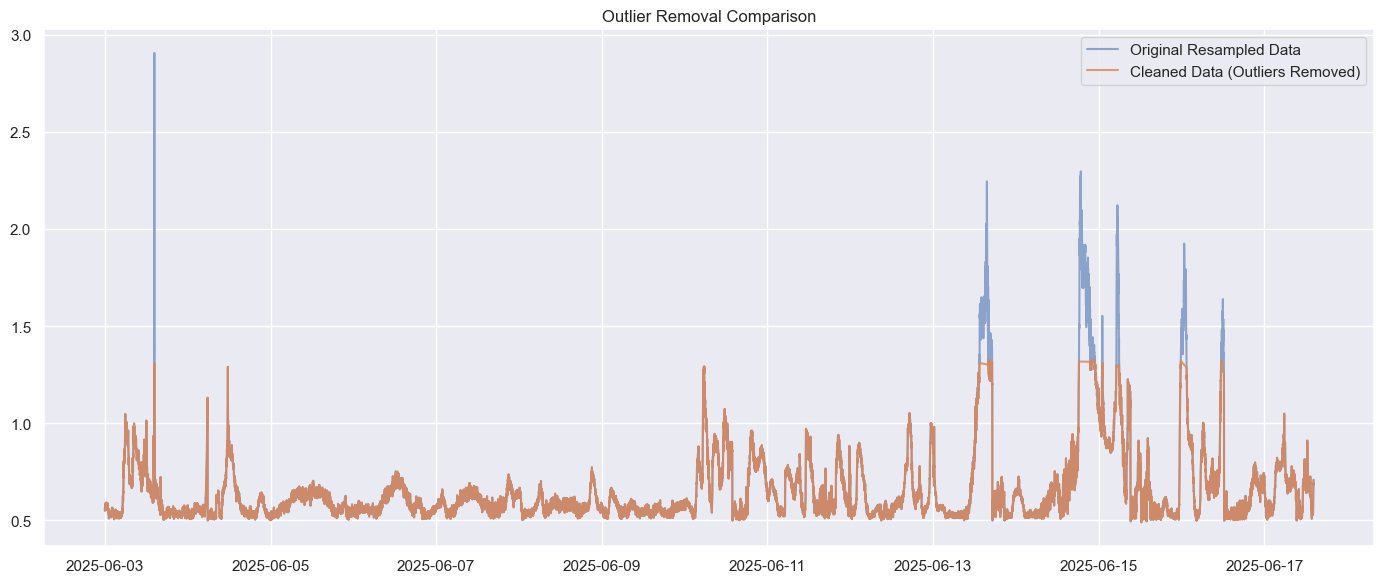

In [35]:
# ======================================
# OUTLIER DETECTION USING Z-SCORE ON RESAMPLED DATA
# ======================================
df_1min_z = df_1min.to_frame()  # Convert to DataFrame
df_1min_z['z_score'] = zscore(df_1min_z['value'].fillna(method='ffill'))

# IDENTIFY OUTLIERS: abs(z_score) > 3
outliers = df_1min_z[np.abs(df_1min_z['z_score']) > 3]
print(f"Number of outliers detected: {len(outliers)}")

# REMOVE OUTLIERS
df_clean = df_1min_z[np.abs(df_1min_z['z_score']) <= 3]['value']

# PLOT ORIGINAL VS CLEANED DATA
plt.figure(figsize=(14, 6))
plt.plot(df_1min, label='Original Resampled Data', alpha=0.6)
plt.plot(df_clean, label='Cleaned Data (Outliers Removed)', alpha=0.8)
plt.legend()
plt.title('Outlier Removal Comparison')
plt.grid(True)
plt.tight_layout()
plt.savefig("outlier_removal_comparison.png", bbox_inches='tight')
plt.show()


ADF Statistic: -9.69366813571327
p-value: 1.1190641319789929e-16
Critical Values:
   1%: -3.4306716824468984
   5%: -2.8616821724632473
   10%: -2.5668456744952732


ARIMA RMSE: 0.2115
ARIMA MAE: 0.1476


ETS RMSE: 0.2123
ETS MAE: 0.1480


Prophet RMSE: 0.2271
Prophet MAE: 0.1611
SMA RMSE: 0.2085
SMA MAE: 0.1463


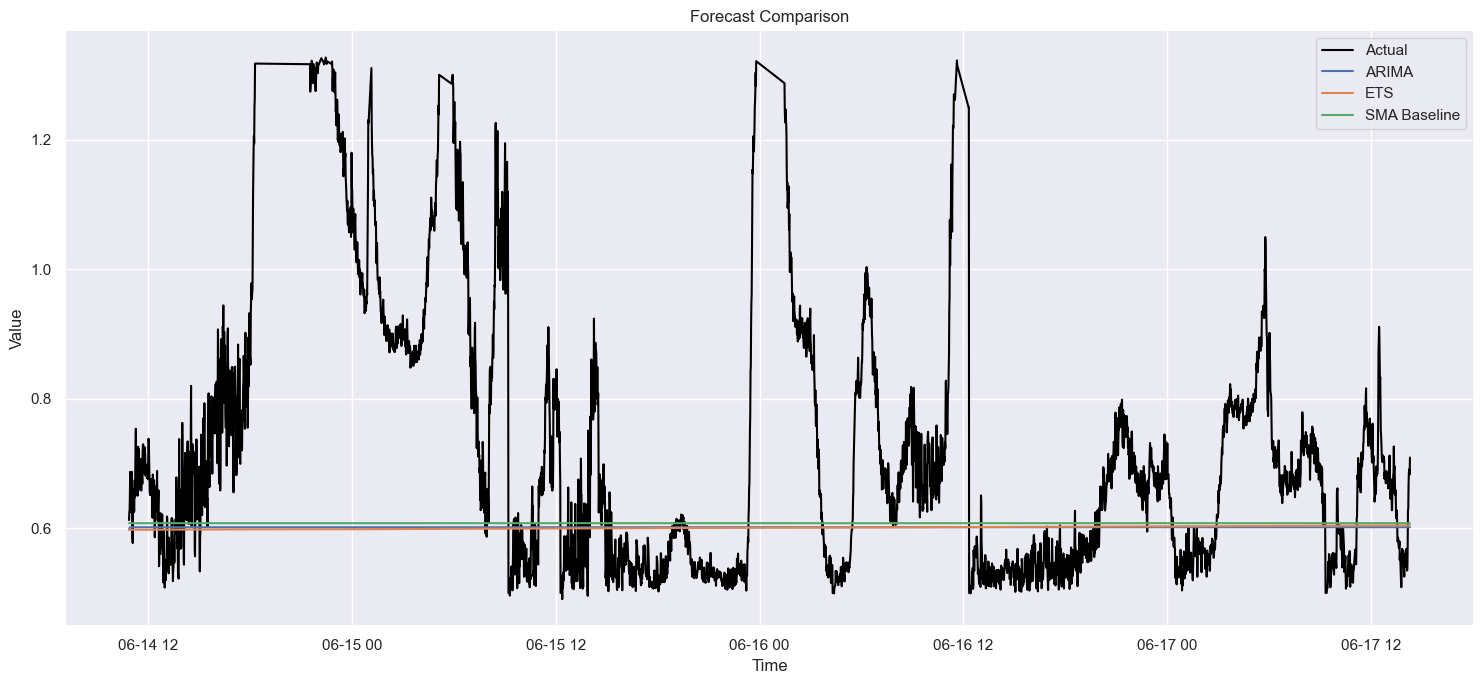

Train data stats:
count    16295.000000
mean         0.616837
std          0.114799
min          0.500000
25%          0.542527
50%          0.576154
75%          0.644402
max          1.326462
Name: value, dtype: float64


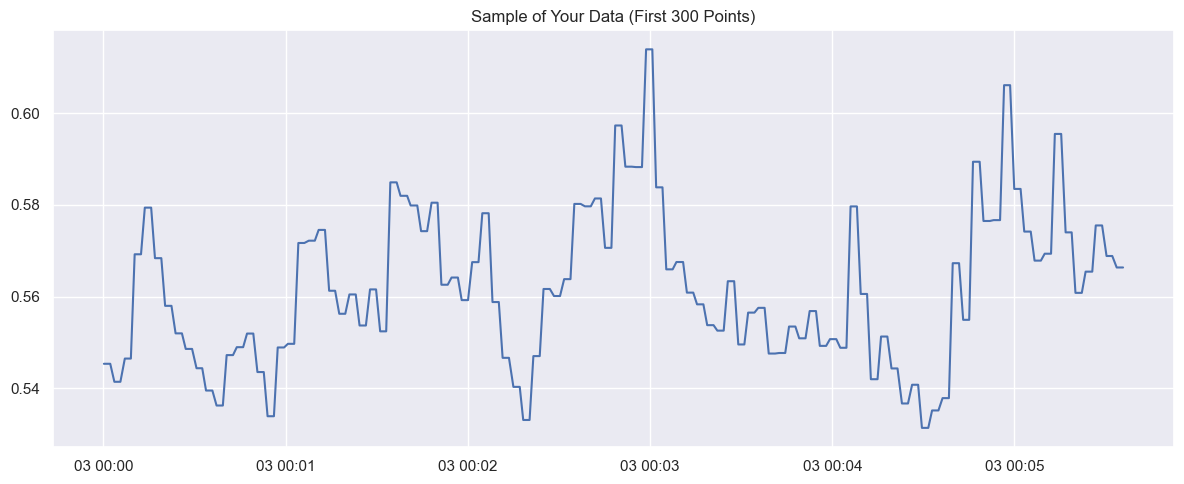

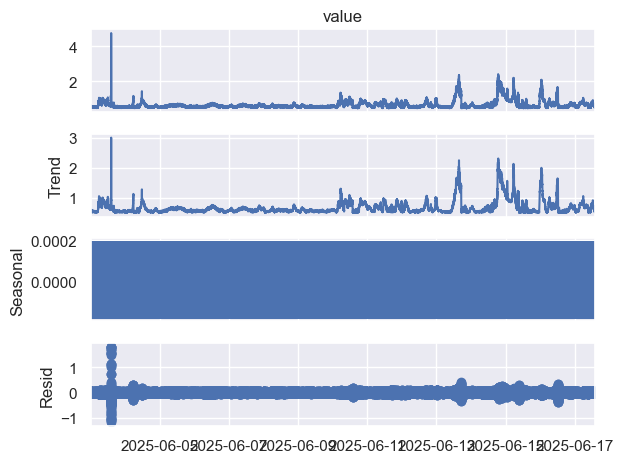

In [ ]:

# ============================
# AUGMENTED DICKEY-FULLER TEST TO CHECK STATIONARITY
# ============================
result = adfuller(df_clean.dropna())
print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:')
for key, value in result[4].items():
    print(f'   {key}: {value}')

# ============================
# TRAIN-TEST SPLIT (80-20)
# ============================
train_size = int(len(df_clean) * 0.8)
train = df_clean[:train_size]
test = df_clean[train_size:]

# ============================
# ARIMA MODEL FITTING AND FORECASTING
# ============================
model_arima = ARIMA(train, order=(1,1,1))
model_arima_fit = model_arima.fit()
forecast_arima = model_arima_fit.forecast(steps=len(test))

rmse_arima = np.sqrt(mean_squared_error(test, forecast_arima))
mae_arima = mean_absolute_error(test, forecast_arima)

print(f'ARIMA RMSE: {rmse_arima:.4f}')
print(f'ARIMA MAE: {mae_arima:.4f}')

# ============================
# ETS MODEL FITTING AND FORECASTING
# ============================
model_ets = ExponentialSmoothing(train, trend='add', seasonal=None)
model_ets_fit = model_ets.fit()
forecast_ets = model_ets_fit.forecast(len(test))

rmse_ets = np.sqrt(mean_squared_error(test, forecast_ets))
mae_ets = mean_absolute_error(test, forecast_ets)

print(f'ETS RMSE: {rmse_ets:.4f}')
print(f'ETS MAE: {mae_ets:.4f}')

# ============================
# PROPHET MODEL FITTING AND FORECASTING
# ============================
df_prophet = train.reset_index().rename(columns={'time': 'ds', 'value': 'y'})
df_prophet['ds'] = pd.to_datetime(df_prophet['ds']).dt.tz_localize(None)

model_prophet = Prophet()
model_prophet.fit(df_prophet)

future = model_prophet.make_future_dataframe(periods=len(test), freq='T')
forecast_prophet = model_prophet.predict(future)

forecast_values = forecast_prophet['yhat'][-len(test):].values

rmse_prophet = np.sqrt(mean_squared_error(test, forecast_values))
mae_prophet = mean_absolute_error(test, forecast_values)

print(f'Prophet RMSE: {rmse_prophet:.4f}')
print(f'Prophet MAE: {mae_prophet:.4f}')

# ============================
# SIMPLE MOVING AVERAGE (SMA) BASELINE FORECAST
# ============================
window_size = 5
sma_forecast = train.rolling(window=window_size).mean().iloc[-1]
sma_forecast_values = np.repeat(sma_forecast, len(test))

rmse_sma = np.sqrt(mean_squared_error(test, sma_forecast_values))
mae_sma = mean_absolute_error(test, sma_forecast_values)

print(f'SMA RMSE: {rmse_sma:.4f}')
print(f'SMA MAE: {mae_sma:.4f}')

# ============================
# PLOT FORECAST COMPARISON
# ============================
plt.figure(figsize=(15, 7))
plt.plot(test.index, test, label='Actual', color='black')
plt.plot(test.index, forecast_arima, label='ARIMA')
plt.plot(test.index, forecast_ets, label='ETS')
# Uncomment the next line to plot Prophet forecast as well
# plt.plot(test.index, forecast_values, label='Prophet')
plt.plot(test.index, sma_forecast_values, label='SMA Baseline')
plt.legend()
plt.title('Forecast Comparison')
plt.xlabel('Time')
plt.ylabel('Value')
plt.grid(True)
plt.tight_layout()
plt.savefig("forecast_comparison.png", bbox_inches='tight')
plt.show()

# ============================
# TRAIN DATA STATISTICS
# ============================
print("Train data stats:")
print(train.describe())

# ============================
# PLOT SAMPLE OF RAW DATA (FIRST 300 POINTS)
# ============================
plt.figure(figsize=(12, 5))
plt.plot(df['value'][:300])
plt.title('Sample of Your Data (First 300 Points)')
plt.grid(True)
plt.tight_layout()
plt.savefig("sample_data_300points.png", bbox_inches='tight')
plt.show()

# ============================
# SEASONAL DECOMPOSITION PLOT (Additive Model)
# ============================
result = seasonal_decompose(df['value'], model='additive', period=60)  # Adjust period if needed
result.plot()
plt.tight_layout()
plt.savefig("seasonal_decompose.png", bbox_inches='tight')
plt.show()


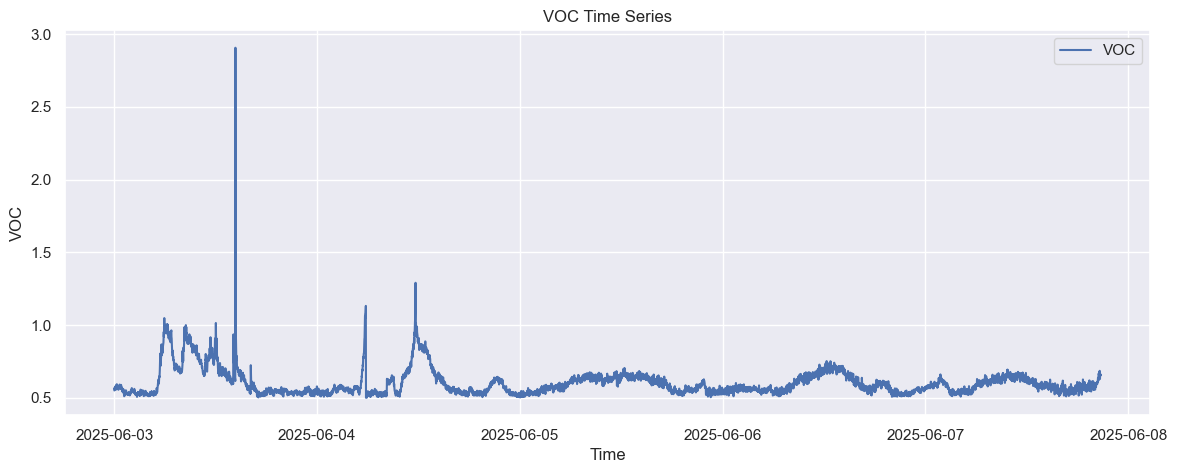

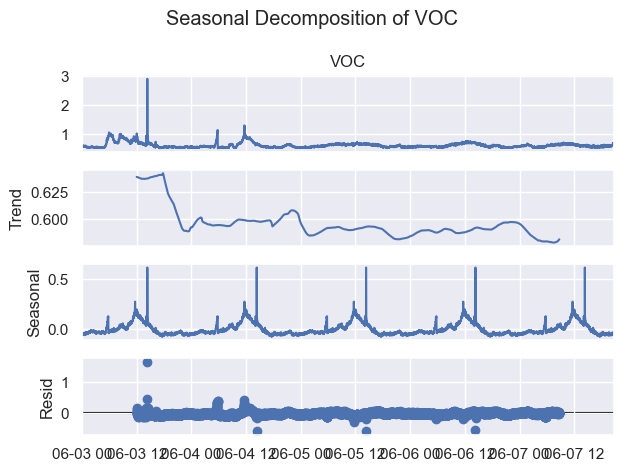

ADF Statistic: -5.199021985037093
p-value: 8.832595412787984e-06
Critical Value 1%: -3.431286133907351
Critical Value 5%: -2.861953695866596
Critical Value 10%: -2.566990206350145


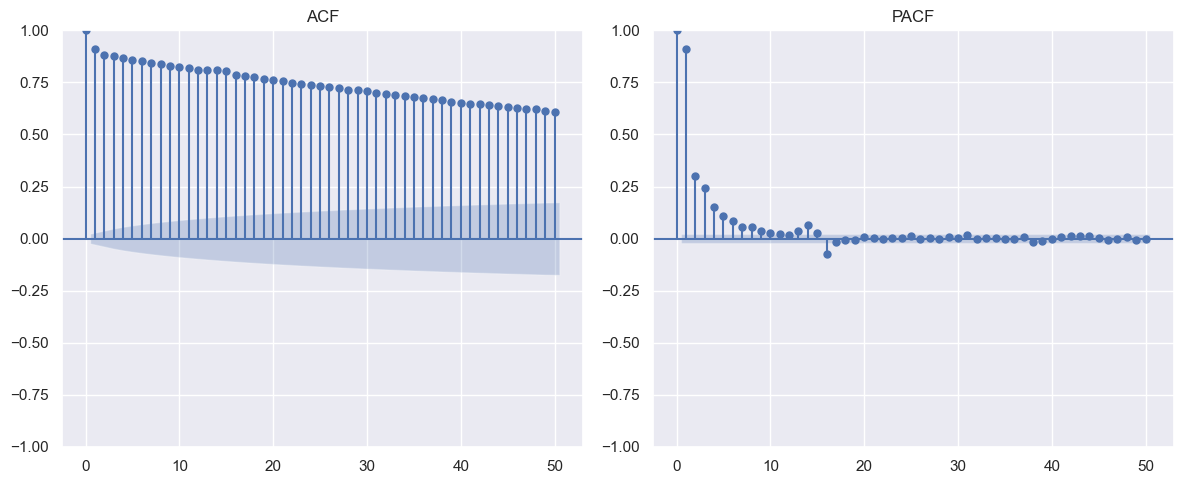

Fitting Auto ARIMA model...
Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-27402.600, Time=2.32 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-25675.075, Time=0.75 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-26493.273, Time=0.44 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-27213.314, Time=2.03 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-25677.074, Time=0.37 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-27404.832, Time=10.69 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=-26981.123, Time=0.99 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=-27408.082, Time=15.91 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=-27164.055, Time=3.85 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=-27401.985, Time=17.13 sec
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-27404.609, Time=7.73 sec
 ARIMA(3,1,1)(0,0,0)[0]             : AIC=-27410.932, Time=5.35 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=-27406.822, Time=1.78 sec
 ARIMA(3,1,0)(0,0,0)[0]             : AIC=

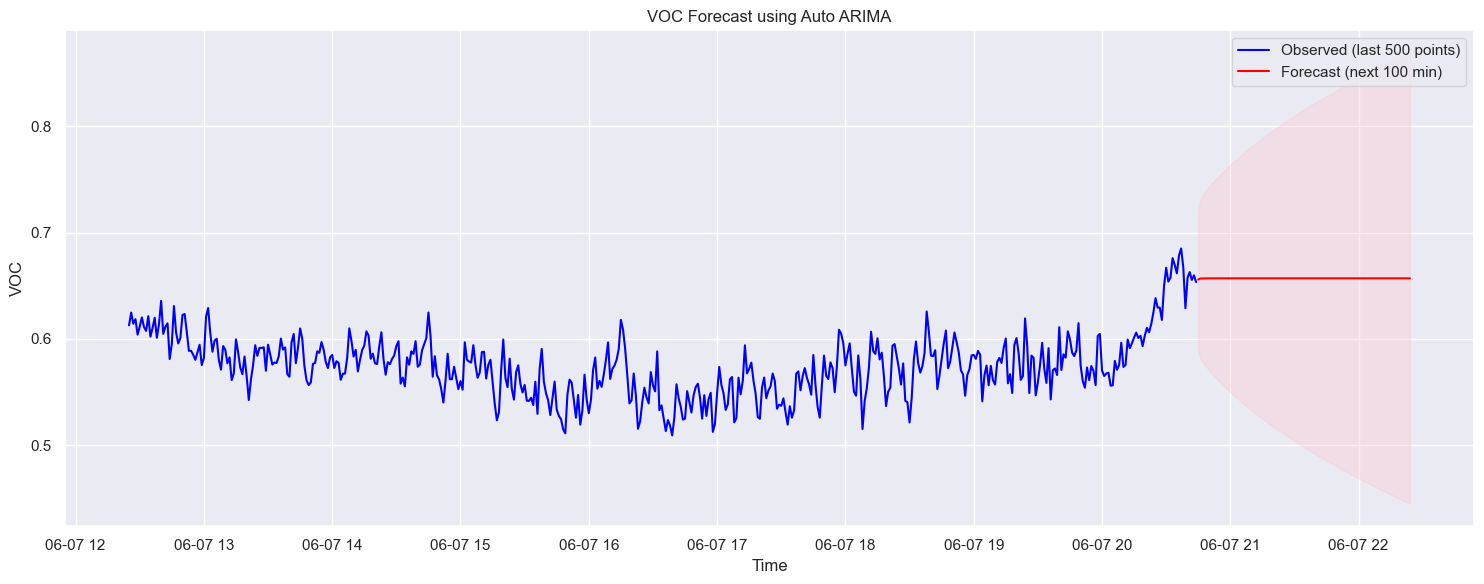

In [5]:
# --- Load and Prepare Data ---
df = pd.read_csv('../data/sensors_1min.csv')
df['time'] = pd.to_datetime(df['time'], utc=True)
df.set_index('time', inplace=True)

# Focus on VOC series, set frequency to 1 minute
voc_series = df['VOC'].asfreq('1min')

# --- Visualize Original VOC Time Series ---
plt.figure(figsize=(14, 5))
plt.plot(voc_series, label='VOC')
plt.title("VOC Time Series")
plt.xlabel("Time")
plt.ylabel("VOC")
plt.grid(True)
plt.legend()
plt.show()

# --- Seasonal Decomposition (Additive Model) ---
result = seasonal_decompose(voc_series.dropna(), model='additive', period=1440)  # daily seasonality
result.plot()
plt.suptitle("Seasonal Decomposition of VOC")
plt.tight_layout()
plt.show()

# --- Stationarity Check with Augmented Dickey-Fuller Test ---
result_adf = adfuller(voc_series.dropna())
print("ADF Statistic:", result_adf[0])
print("p-value:", result_adf[1])
for key, value in result_adf[4].items():
    print(f'Critical Value {key}: {value}')

# --- Plot ACF and PACF ---
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plot_acf(voc_series.dropna(), ax=plt.gca(), lags=50)
plt.title("ACF")

plt.subplot(1,2,2)
plot_pacf(voc_series.dropna(), ax=plt.gca(), lags=50, method='ywm')
plt.title("PACF")
plt.tight_layout()
plt.show()

# --- Fit Auto ARIMA Model ---
print("Fitting Auto ARIMA model...")
model = auto_arima(
    voc_series.dropna(),
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    seasonal=False,
    d=1,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)
print(model.summary())

# --- Forecast Next 100 Minutes ---
n_periods = 100
forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)

# Create datetime index for forecast
last_timestamp = voc_series.index[-1]
forecast_index = pd.date_range(start=last_timestamp + pd.Timedelta(minutes=1), periods=n_periods, freq='1min')
forecast_series = pd.Series(forecast, index=forecast_index)

# --- Plot Forecast Against Recent Observations ---
plt.figure(figsize=(15, 6))
plt.plot(voc_series[-500:], label='Observed (last 500 points)', color='blue')
plt.plot(forecast_series, label='Forecast (next 100 min)', color='red')
plt.fill_between(forecast_index, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3)
plt.title("VOC Forecast using Auto ARIMA")
plt.xlabel("Time")
plt.ylabel("VOC")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
